# Лабораторна робота №2
## Візуалізація даних у Matplotlib
**Виконав:** Максим Бологов  
**Варіант:** 3  
**Справа:** №3 — «Рожева річка Тиха»

### Мета роботи
Побудувати графіки різних типів засобами Matplotlib, проаналізувати дані чотирьох свідків і визначити підприємство, причетне до забруднення річки та ґрунту.

In [11]:
import json
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

CASE = 'case_03/'
os.makedirs('figures', exist_ok=True)

ents = pd.read_csv(CASE + 'enterprises.csv', encoding='utf-8')
posts = pd.read_csv(CASE + 'posts.csv', encoding='utf-8')
river = pd.read_csv(CASE + 'river.csv', encoding='utf-8')
outflow = pd.read_csv(CASE + 'outflow.csv', encoding='utf-8')
samples = pd.read_csv(CASE + 'samples.csv', encoding='utf-8')
types = pd.read_csv(CASE + 'dye_types.csv', encoding='utf-8')
soil = pd.read_csv(CASE + 'soil.csv', encoding='utf-8')
with open(CASE + 'case.json', encoding='utf-8') as f:
    case = json.load(f)

print('Номер справи:', case['n'])
print('Підприємства:')
display(ents)
print('Пости на річці:')
display(posts)
print('Типи барвників:')
display(types)

Номер справи: 3
Підприємства:


,id,name,short,dye_type,outfall_km,x_km,y_km,dye_kg_month
0,E1,панчішна фабрика «Смугастий борсук»,Смугастий борсук,текстильний,13.2,2.18,2.24,470
1,E2,шовкова фабрика «Шовковий бегемот»,Шовковий бегемот,текстильний,19.4,2.17,3.11,190
2,E3,друкарня «Курсивний папуга»,Курсивний папуга,поліграфічний,2.5,1.08,0.46,110
3,E4,пакувальна фабрика «Картонний мамонт»,Картонний мамонт,поліграфічний,35.7,4.50,5.16,280
4,E5,друкарня «Чорнильний дикобраз»,Чорнильний дикобраз,поліграфічний,25.5,1.73,4.77,130
5,E6,трикотажна фабрика «Вовняний маяк»,Вовняний маяк,текстильний,17.8,4.27,1.55,320
6,E7,килимарня «Килимовий дирижабль»,Килимовий дирижабль,текстильний,24.2,3.13,2.71,180
7,E8,типографія «Шрифтовий кашалот»,Шрифтовий кашалот,поліграфічний,14.6,1.53,2.73,310


Пости на річці:


,post,km
0,пост 1,0.0
1,пост 2,10.3
2,пост 3,20.8
3,пост 4,30.1
4,пост 5,39.2


Типи барвників:


,dye_type,k
0,текстильний,1.81
1,харчовий,0.92
2,поліграфічний,0.44


## Етап А. Таблиця мовчить

Виводимо описову статистику добових обсягів скидів для кожного підприємства.

In [12]:
outflow.groupby('id')['m3'].describe().round(1)

,count,mean,std,min,25%,50%,75%,max
id,,,,,,,,
E1,180.0,520.0,80.9,120.0,470.0,520.0,570.0,920.0
E2,180.0,520.0,80.9,120.0,470.0,520.0,570.0,920.0
E3,180.0,520.0,80.9,120.0,470.0,520.0,570.0,920.0
E4,180.0,520.0,80.9,120.0,470.0,520.0,570.0,920.0
E5,180.0,520.0,80.9,120.0,470.0,520.0,570.0,920.0
E6,180.0,520.0,80.9,120.0,470.0,520.0,570.0,920.0
E7,180.0,520.0,80.9,120.0,470.0,520.0,570.0,920.0
E8,180.0,520.0,80.9,120.0,470.0,520.0,570.0,920.0


**Відповідь:** У всіх восьми підприємств однакові зведені показники: кількість спостережень — 180, середнє — 520, стандартне відхилення — 80,9, мінімум — 120, квартилі — 470, 520 і 570, максимум — 920 м³. За цією таблицею винного визначити неможливо, оскільки показники журналів штучно зроблені однаковими. Для пошуку відмінностей потрібно порівняти розподіли на гістограмах.

## Етап Б. Річка

Будуємо два графіки в одній фігурі: зверху — усі 336 годин спостережень, знизу — збільшення першої ділянки зі спайком.

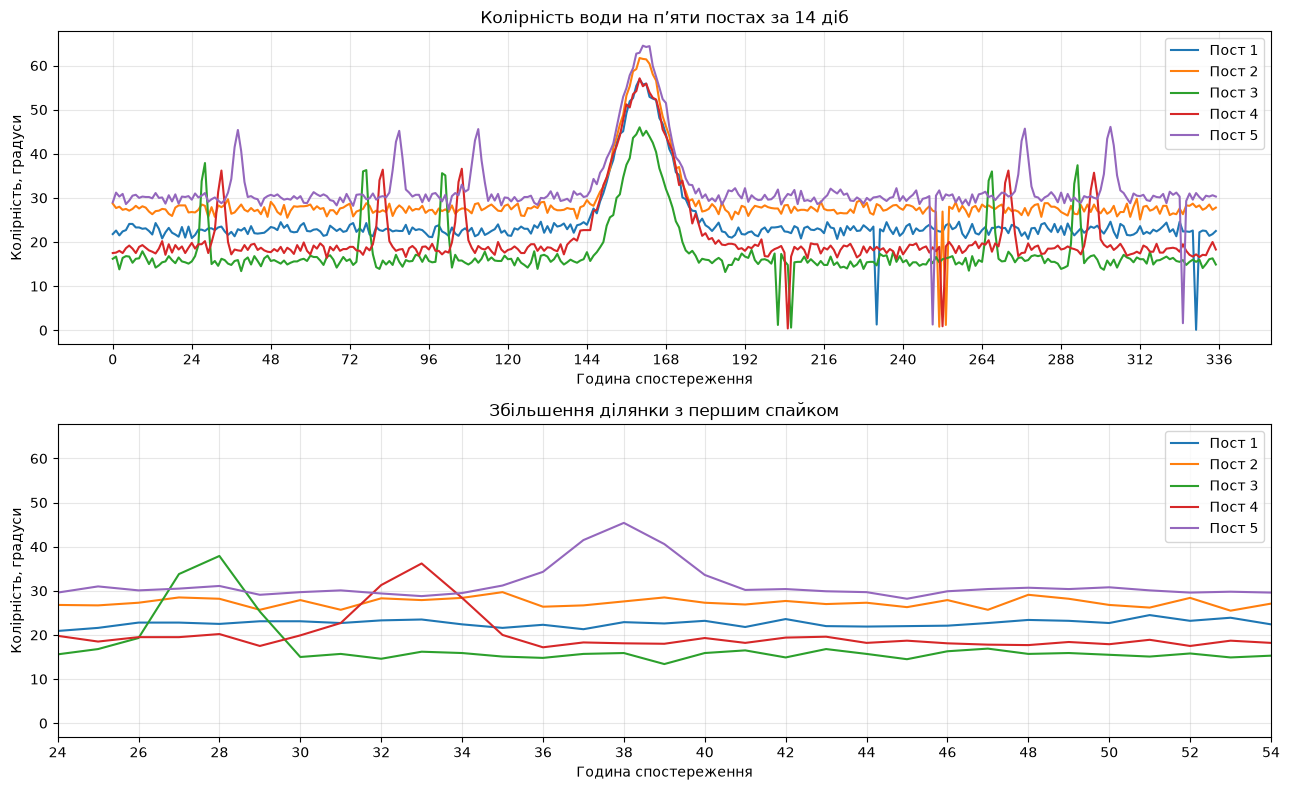

In [13]:
plt.figure(figsize=(13, 8))

plt.subplot(2, 1, 1)
for i in range(1, 6):
    plt.plot(river['hour'], river[f'post_{i}'], label=f'Пост {i}')
plt.title('Колірність води на п’яти постах за 14 діб')
plt.xlabel('Година спостереження')
plt.ylabel('Колірність, градуси')
plt.xticks(range(0, 337, 24))
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(2, 1, 2)
for i in range(1, 6):
    plt.plot(river['hour'], river[f'post_{i}'], label=f'Пост {i}')
plt.title('Збільшення ділянки з першим спайком')
plt.xlabel('Година спостереження')
plt.ylabel('Колірність, градуси')
plt.xlim(24, 54)
plt.xticks(range(24, 55, 2))
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('figures/B_river.png', bbox_inches='tight')
plt.show()

**Відповідь:**

1. Перший виразний спайк з’являється на **посту 3** приблизно на 28-й годині. Попередній пост — пост 2 (10,3 км), пост 3 розташований на 20,8 км. Отже, скид стався між 10,3 і 20,8 км. На цій ділянці розташовані чотири підприємства:
   - Смугастий борсук — 13,2 км;
   - Шовковий бегемот — 19,4 км;
   - Вовняний маяк — 17,8 км;
   - Шрифтовий кашалот — 14,6 км.
2. Горб не є скидом, тому що це плавне підвищення колірності, яке одночасно спостерігається на всіх постах протягом тривалого часу. Скид барвника має вигляд короткого різкого спайка, який послідовно доходить до постів нижче за течією.

## Етап В. Журнали скидів

Порівнюємо розподіли добових обсягів скидів. Спочатку будуємо гістограми з типовими 10 інтервалами, потім — із 40 інтервалами.

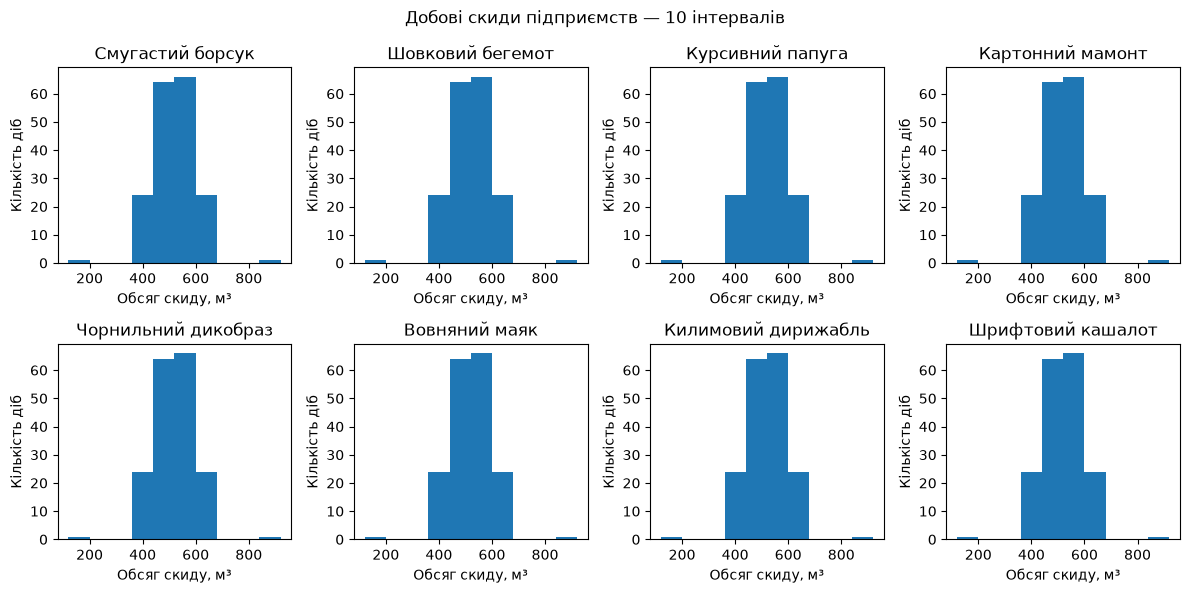

In [14]:
plt.figure(figsize=(12, 6))
for k in range(1, 9):
    plt.subplot(2, 4, k)
    current_id = ents.iloc[k - 1]['id']
    plt.hist(outflow[outflow['id'] == current_id]['m3'])
    plt.title(ents.iloc[k - 1]['short'])
    plt.xlabel('Обсяг скиду, м³')
    plt.ylabel('Кількість діб')
plt.suptitle('Добові скиди підприємств — 10 інтервалів')
plt.tight_layout()
plt.savefig('figures/V1_hist10.png', bbox_inches='tight')
plt.show()

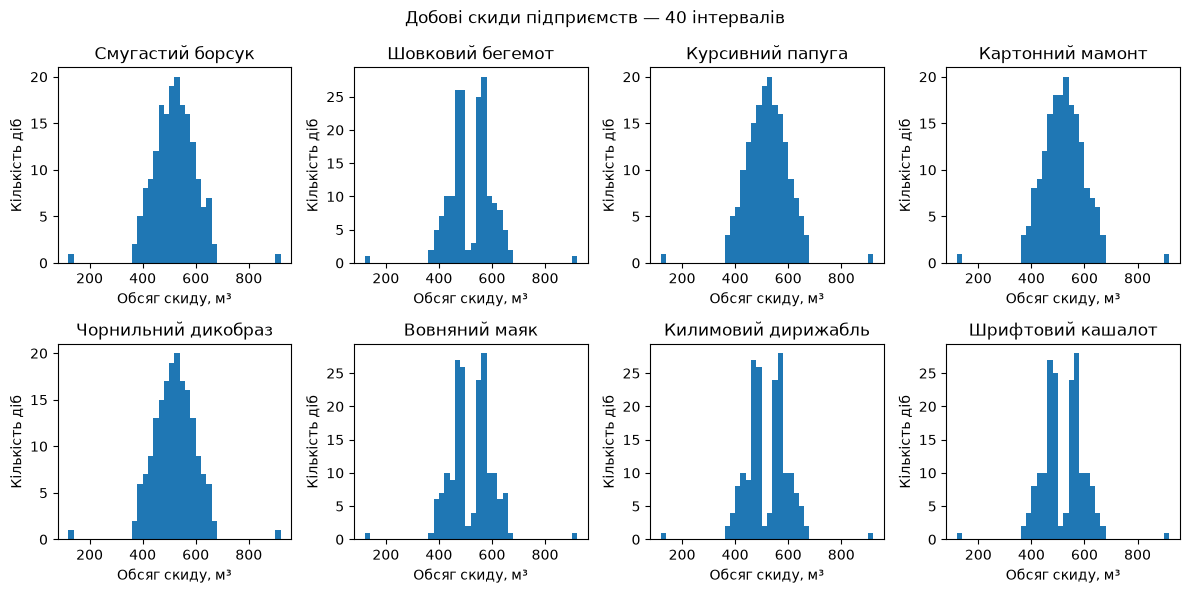

In [15]:
plt.figure(figsize=(12, 6))
for k in range(1, 9):
    plt.subplot(2, 4, k)
    current_id = ents.iloc[k - 1]['id']
    plt.hist(outflow[outflow['id'] == current_id]['m3'], bins=40)
    plt.title(ents.iloc[k - 1]['short'])
    plt.xlabel('Обсяг скиду, м³')
    plt.ylabel('Кількість діб')
plt.suptitle('Добові скиди підприємств — 40 інтервалів')
plt.tight_layout()
plt.savefig('figures/V2_hist40.png', bbox_inches='tight')
plt.show()

**Відповідь:**

1. На гістограмах із 40 інтервалами дві виразні вершини мають підприємства **Шовковий бегемот, Вовняний маяк, Килимовий дирижабль і Шрифтовий кашалот**. Це підприємства, які працювали у двох режимах скидання, тому вони залишаються під підозрою.
2. Зведена таблиця показує лише основні числові характеристики розподілу. Різні розподіли можуть мати однакові середнє, стандартне відхилення, мінімум, максимум і квартилі.
3. На гістограмі з 10 інтервалами два скупчення об’єднуються в ширші стовпчики. Через малу кількість інтервалів дві вершини не розрізняються так чітко.

## Етап Г. Хімічний відбиток

Кожна точка — проба води. По горизонталі відкладаємо червоний барвник, по вертикалі — синій. Спочатку знаходимо центр фонової групи проб, а потім проводимо прямі з нахилами трьох типів барвника.

Центр фону A0 = 3.7 мг/л; B0 = 1.7 мг/л


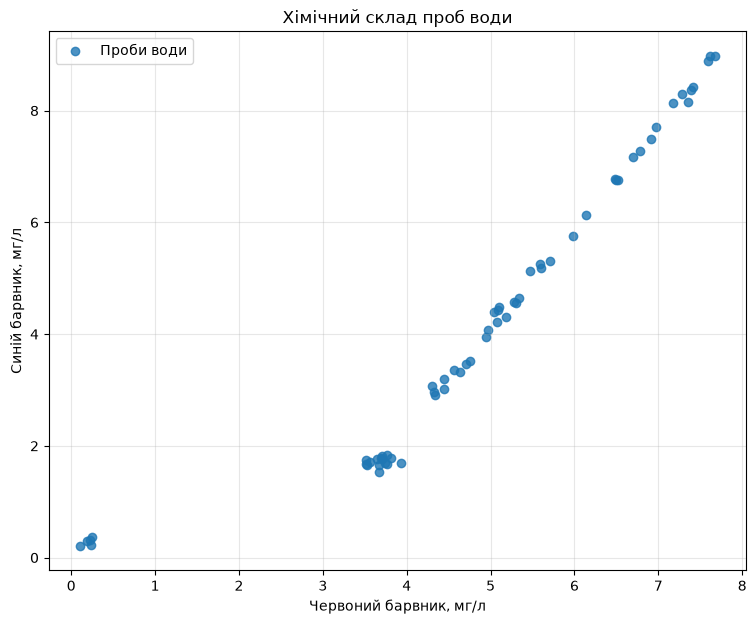

In [16]:
# Фонові проби утворюють групу з red приблизно від 3.4 до 4.0 мг/л.
background = samples[(samples['red'] > 3.4) & (samples['red'] < 4.0)]
A0 = round(background['red'].mean(), 1)
B0 = round(background['blue'].mean(), 1)

print('Центр фону A0 =', A0, 'мг/л; B0 =', B0, 'мг/л')

plt.figure(figsize=(9, 7))
plt.scatter(samples['red'], samples['blue'], alpha=0.8, label='Проби води')
plt.title('Хімічний склад проб води')
plt.xlabel('Червоний барвник, мг/л')
plt.ylabel('Синій барвник, мг/л')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

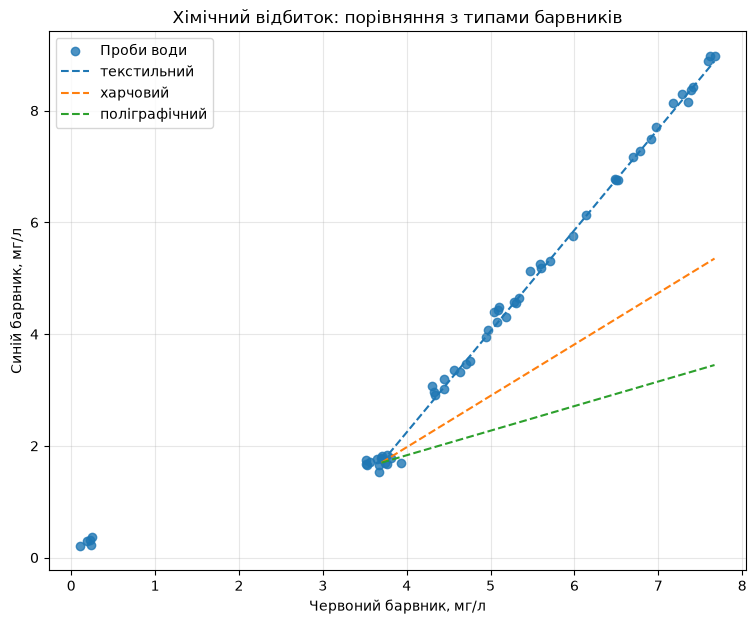

In [17]:
xmax = samples['red'].max()

plt.figure(figsize=(9, 7))
plt.scatter(samples['red'], samples['blue'], alpha=0.8, label='Проби води')
for i in range(len(types)):
    k = types.iloc[i]['k']
    plt.plot([A0, xmax], [B0, B0 + k * (xmax - A0)], '--',
             label=types.iloc[i]['dye_type'])
plt.title('Хімічний відбиток: порівняння з типами барвників')
plt.xlabel('Червоний барвник, мг/л')
plt.ylabel('Синій барвник, мг/л')
plt.legend()
plt.grid(True, alpha=0.3)
plt.savefig('figures/G_chem.png', bbox_inches='tight')
plt.show()

**Відповідь:** Центр фонової групи проб приблизно **A0 = 3,7 мг/л**, **B0 = 1,7 мг/л**. Смуга проб під час скидів прямує вздовж прямої з нахилом, близьким до **k = 1,81**. Це **текстильний** барвник.

Текстильний барвник використовують чотири підприємства:
- Смугастий борсук;
- Шовковий бегемот;
- Вовняний маяк;
- Килимовий дирижабль.

## Етап Д. Ґрунт

Перетворюємо таблицю вимірювань на матрицю, будуємо кольорову карту концентрації барвника та лінію нормативного значення 35 мг/кг.

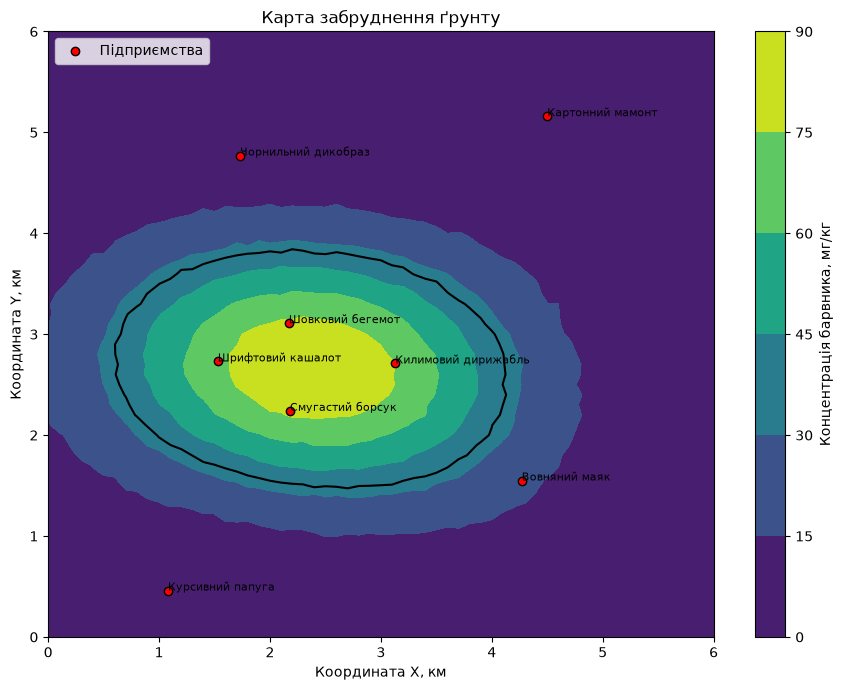

In [18]:
Z = soil.pivot(index='y', columns='x', values='c')
X, Y = np.meshgrid(Z.columns, Z.index)

plt.figure(figsize=(9, 7))
cont = plt.contourf(X, Y, Z)
plt.colorbar(cont, label='Концентрація барвника, мг/кг')
plt.contour(X, Y, Z, levels=[case['soil_limit']], colors='black')
plt.scatter(ents['x_km'], ents['y_km'], color='red', edgecolor='black', label='Підприємства')

for i in range(len(ents)):
    plt.text(ents.iloc[i]['x_km'], ents.iloc[i]['y_km'],
             ents.iloc[i]['short'], fontsize=8)

plt.title('Карта забруднення ґрунту')
plt.xlabel('Координата X, км')
plt.ylabel('Координата Y, км')
plt.legend(loc='upper left')
plt.tight_layout()
plt.savefig('figures/D_soil.png', bbox_inches='tight')
plt.show()

**Відповідь:** Усередині лінії нормативу 35 мг/кг розташовані чотири підприємства:
- Смугастий борсук;
- Шовковий бегемот;
- Килимовий дирижабль;
- Шрифтовий кашалот.

Саме ці підприємства залишаються під підозрою за свідченням ґрунту. Карта вказує на місце забруднення, але сама по собі не визначає винного.

## Етап Е. Рапорт

Підраховуємо, скільки з чотирьох свідків залишили кожне підприємство під підозрою. Праворуч показуємо частки закупівель барвника чотирма підприємствами, визначеними за хімічним відбитком.

In [19]:
river_four = ents[(ents['outfall_km'] > 10.3) & (ents['outfall_km'] < 20.8)]
hist_four = ents[ents['id'].isin(['E2', 'E6', 'E7', 'E8'])]
chem_four = ents[ents['dye_type'] == 'текстильний']
soil_four = ents[ents['id'].isin(['E1', 'E2', 'E7', 'E8'])]

river_list = list(river_four['short'])
hist_list = list(hist_four['short'])
chem_list = list(chem_four['short'])
soil_list = list(soil_four['short'])

votes = []
for name in ents['short']:
    v = 0
    for lst in [river_list, hist_list, chem_list, soil_list]:
        if name in lst:
            v = v + 1
    votes.append(v)

print('Річка:', river_list)
print('Гістограми:', hist_list)
print('Хімія:', chem_list)
print('Ґрунт:', soil_list)
print(pd.DataFrame({'Підприємство': ents['short'], 'Кількість свідків': votes}))

Річка: ['Смугастий борсук', 'Шовковий бегемот', 'Вовняний маяк', 'Шрифтовий кашалот']
Гістограми: ['Шовковий бегемот', 'Вовняний маяк', 'Килимовий дирижабль', 'Шрифтовий кашалот']
Хімія: ['Смугастий борсук', 'Шовковий бегемот', 'Вовняний маяк', 'Килимовий дирижабль']
Ґрунт: ['Смугастий борсук', 'Шовковий бегемот', 'Килимовий дирижабль', 'Шрифтовий кашалот']
          Підприємство  Кількість свідків
0     Смугастий борсук                  3
1     Шовковий бегемот                  4
2     Курсивний папуга                  0
3     Картонний мамонт                  0
4  Чорнильний дикобраз                  0
5        Вовняний маяк                  3
6  Килимовий дирижабль                  3
7    Шрифтовий кашалот                  3


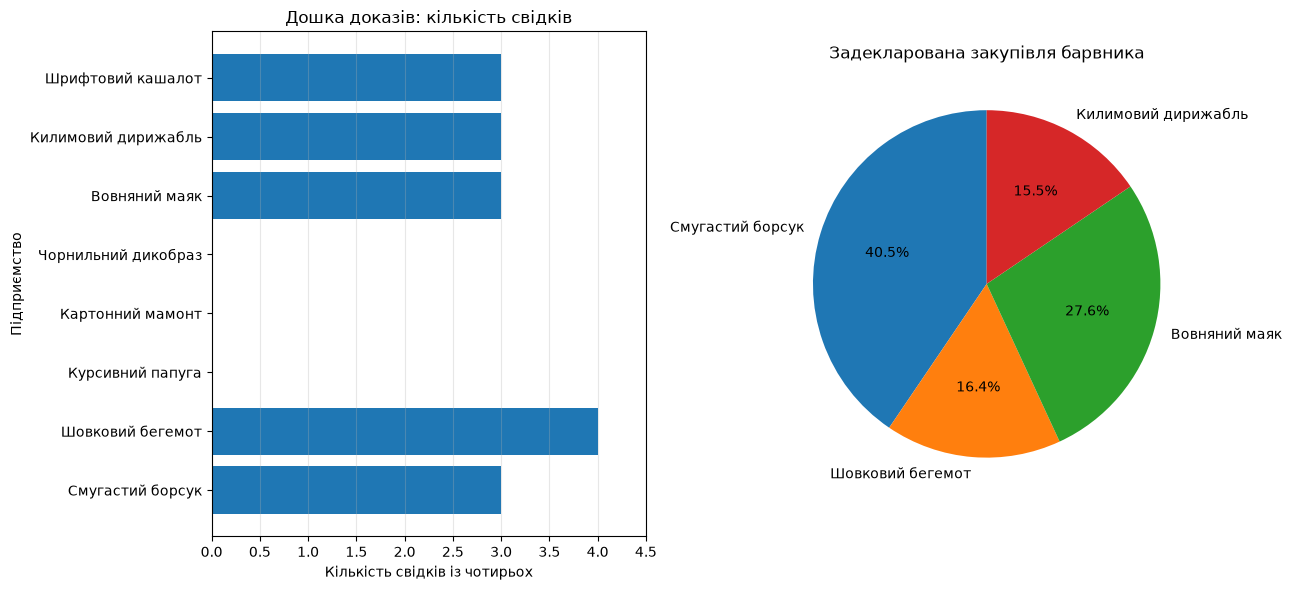

In [20]:
plt.figure(figsize=(13, 6))

plt.subplot(1, 2, 1)
plt.barh(ents['short'], votes)
plt.title('Дошка доказів: кількість свідків')
plt.xlabel('Кількість свідків із чотирьох')
plt.ylabel('Підприємство')
plt.xlim(0, 4.5)
plt.grid(axis='x', alpha=0.3)

plt.subplot(1, 2, 2)
plt.pie(chem_four['dye_kg_month'],
        labels=chem_four['short'],
        autopct='%1.1f%%',
        startangle=90)
plt.title('Задекларована закупівля барвника')

plt.tight_layout()
plt.savefig('figures/E_report.png', bbox_inches='tight')
plt.show()

### Висновок

У ході лабораторної роботи було проаналізовано чотири набори доказів у справі №3 «Рожева річка Тиха». Для цього використано лінійні графіки, гістограми, діаграму розсіювання, контурну карту та комбіновану фігуру з горизонтальною стовпчиковою і круговою діаграмами.

За результатами перевірки:
- річка залишила під підозрою чотири підприємства, розташовані між постами 2 і 3;
- гістограми показали два режими скидання у чотирьох підприємств;
- хімічний відбиток указав на текстильний тип барвника;
- карта ґрунту визначила чотири підприємства в межах забрудненої ділянки.

**Винним є підприємство «Шовковий бегемот»** — воно отримало 4 голоси з 4 можливих.

За звітами найбільше барвника серед чотирьох підприємств із текстильним типом закуповує **«Смугастий борсук»** — 470 кг на місяць. Однак його виключив свідок-гістограма, оскільки воно не має двох виразних вершин на гістограмі з 40 інтервалами.

| Етап | Тип графіка | Чому використано |
|---|---|---|
| Б — річка | Лінійний графік | Показує зміну колірності води в часі та затримку спайка між постами |
| В — скиди | Гістограма | Показує розподіл обсягів скидів і два режими роботи |
| Г — хімія | Діаграма розсіювання та лінії | Дає змогу порівняти пропорції червоного й синього барвників |
| Д — ґрунт | Контурна кольорова карта | Показує просторове поширення забруднення та межу нормативу |
| Е — рапорт | Горизонтальна стовпчикова та кругова діаграми | Порівнює кількість доказів і частки закупівель барвника |

Отже, мети лабораторної роботи досягнуто: побудовано графіки різних типів, проаналізовано дані та визначено підприємство, яке не виключив жоден із чотирьох свідків.